# Évaluation des politiques par rang

Expériences sur données synthétiques pour étudier les valeurs par rang, les métriques agrégées et la sélection des modèles. Les cellules sont organisées pour pouvoir lancer chaque expérience séparément.


## 1. Profils de réponse

On compare quatre classements qui partagent le même premier traitement. Les courbes montrent les valeurs par rang et leurs sommes cumulées.


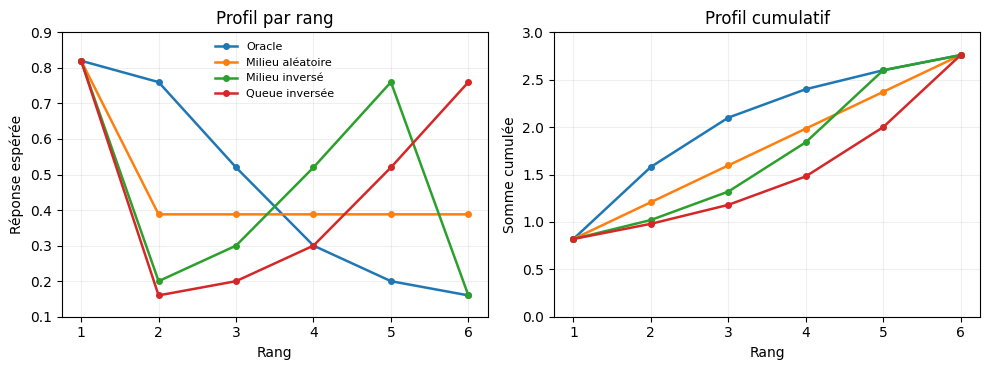

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rangs = np.arange(1, 7)

oracle = np.array([0.82, 0.76, 0.52, 0.30, 0.20, 0.16])

profils = {
    "Oracle": oracle,
    "Milieu aléatoire": np.array([
        0.82, *([np.mean(oracle[1:])] * 5)
    ]),
    "Milieu inversé": oracle[[0, 4, 3, 2, 1, 5]],
    "Queue inversée": oracle[[0, 5, 4, 3, 2, 1]],
}

K = len(rangs)
poids = 2 * (K - rangs + 1) / (K * (K + 1))

for nom, profil in profils.items():
    R = np.dot(poids, profil)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

couleurs = {
    "Oracle": "tab:blue",
    "Milieu aléatoire": "tab:orange",
    "Milieu inversé": "tab:green",
    "Queue inversée": "tab:red",
}

for nom, profil in profils.items():
    couleur = couleurs[nom]

    axes[0].plot(
        rangs, profil,
        marker="o",
        markersize=4,
        linewidth=1.8,
        color=couleur,
        label=nom
    )

    axes[1].plot(
        rangs, np.cumsum(profil),
        marker="o",
        markersize=4,
        linewidth=1.8,
        color=couleur
    )

axes[0].set_title("Profil par rang")
axes[0].set_xlabel("Rang")
axes[0].set_ylabel("Réponse espérée")
axes[0].set_xticks(rangs)
axes[0].set_ylim(0.10, 0.90)
axes[0].legend(fontsize=8, frameon=False)

axes[1].set_title("Profil cumulatif")
axes[1].set_xlabel("Rang")
axes[1].set_ylabel("Somme cumulée")
axes[1].set_xticks(rangs)
axes[1].set_ylim(0, 3.0)

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()

plt.savefig("exp1_profils.pdf", bbox_inches="tight")
plt.show()


## 2. Différences entre les rangs

Les cartes de chaleur représentent les différences $V_r - V_s$ pour le classement oracle et un classement dont les rangs intermédiaires sont inversés.


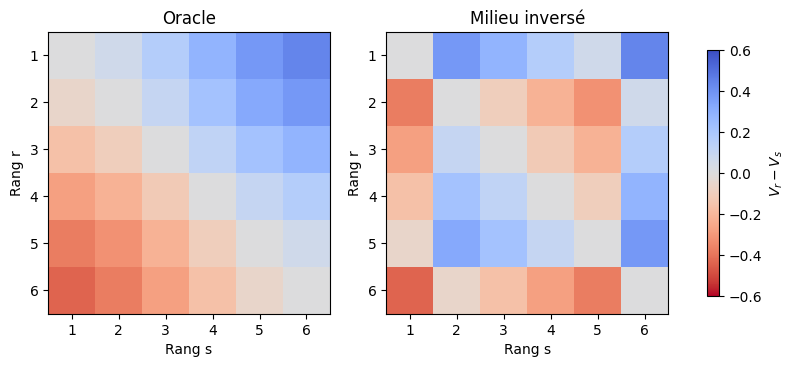

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
K = 6

X = rng.uniform(-1, 1, size=(10000, 2))
angles = np.linspace(0, 2*np.pi, K, endpoint=False)
directions = np.column_stack([np.cos(angles), np.sin(angles)])
mu = np.clip(0.5 + 0.3 * X @ directions.T, 0.1, 0.9)

optimal = np.argsort(-mu, axis=1)
orders = {
    "Oracle": optimal,
    "Milieu inversé": optimal[:, [0, 4, 3, 2, 1, 5]]
}

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, order) in zip(axs, orders.items()):
    V = np.take_along_axis(mu, order, axis=1).mean(axis=0)
    dif = V[:, None] - V[None, :]

    im = ax.imshow(dif, vmin=-0.6, vmax=0.6, cmap="coolwarm_r")
    ax.set(
        title=name,
        xlabel="Rang s",
        ylabel="Rang r",
        xticks=range(K),
        yticks=range(K)
    )
    ax.set_xticklabels(range(1, K+1))
    ax.set_yticklabels(range(1, K+1))

fig.colorbar(im, ax=axs.tolist(), shrink=0.8, label=r"$V_r - V_s$")
plt.savefig("heatmap.pdf", bbox_inches="tight")
plt.show()


## 3. Fonctions

Les expériences suivantes utilisent les mêmes fonctions de génération des données, d’estimation IPW et de calcul des métriques. Les tableaux sont conservés au format CSV et les figures au format PDF.


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone

SEED = 42
MODE = 'quick'
OUT = Path('Chapitres/metriques')
OUT.mkdir(exist_ok=True, parents=True)
REPS = 60 if MODE == 'quick' else 800
K_DILUTION = [2, 4, 8, 16, 32, 64, 128, 256]
K_VARIANCE = [3, 5, 8, 12, 32, 64, 128]
N_GRID = [500, 1000, 2000, 4000, 8000, 16000, 32000, 64000]
plt.rcParams.update({'font.size': 10.5, 'pdf.fonttype': 42})

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close()

def save_table(df, name):
    df.to_csv(OUT / f'{name}.csv', index=False)

def weights(K):
    return 2 * np.arange(K, 0, -1) / (K * (K + 1))

def rank_from_scores(scores):
    return np.argsort(-scores, axis=1, kind='stable')

def ipw_values(order, T, Y, K):
    rank_of_t = np.argsort(order, axis=1)[np.arange(len(T)), T]
    return K * np.bincount(rank_of_t, weights=Y, minlength=K) / len(T)

def oracle_values(order, mu):
    return np.take_along_axis(mu, order, axis=1).mean(axis=0)

def rand_trial(mu, rng):
    n, K = mu.shape
    T = rng.integers(K, size=n)
    Y = (rng.random(n) < mu[np.arange(n), T]).astype(float)
    return T, Y

def kendall(order, mu):
    """Kendall tau-a moyen : moyenne des signes sur toutes les paires de rangs.

    Les ex-aequo contribuent pour 0. Fonction exacte pour tout K >= 2.
    """
    z = np.take_along_axis(mu, order, axis=1)
    n, K = z.shape
    if K < 2:
        return np.nan

    total = 0.0
    for i in range(K - 1):
        total += np.sign(z[:, i, None] - z[:, i + 1:]).sum()

    return total / (n * K * (K - 1) / 2)

def metrics(order, mu, pred=None, q=.2):
    V = oracle_values(order, mu)
    K = len(V)
    w = weights(K)
    bar = V.mean()
    R = V @ w
    fweights = (1 - q) * q ** np.arange(K) / (1 - q ** K) if q else np.eye(1, K, 0).ravel()
    pair = 2 * sum(V[r] - V[s] for r in range(K) for s in range(r + 1, K)) / (K * (K - 1))
    res = dict(V1=V[0], V2=V[1], S=V[0] - V[-1], R=R, DeltaR=R - bar,
               Apair=pair, F02=V @ fweights, Kendall=kendall(order, mu))
    if pred is not None:
        res['RMSE'] = np.sqrt(np.mean((pred - mu) ** 2))
    return res

def dgp_zones_competitives(n, K, rng):
    X = rng.uniform(-1, 1, size=(n, 2))
    angles = np.linspace(0, 2 * np.pi, K, endpoint=False)
    directions = np.column_stack([np.cos(angles), np.sin(angles)])
    score = X @ directions.T
    mu = np.clip(.5 + .35 * score, .05, .95)
    return X, mu

def dgp_2_pertinents_bruit(n, K, rng):
    X = rng.uniform(-1, 1, size=(n, 2))
    mu = np.full((n, K), 0.20)
    mu[:, 0] = np.clip(0.55 + 0.30 * X[:, 0], 0.05, 0.95)
    mu[:, 1] = np.clip(0.55 - 0.30 * X[:, 0], 0.05, 0.95)
    if K > 2:
        angles = np.linspace(0, 2 * np.pi, K - 2, endpoint=False)
        dirs = np.column_stack([np.cos(angles), np.sin(angles)])
        mu[:, 2:] = np.clip(0.20 + 0.08 * (X @ dirs.T), 0.05, 0.45)
    return X, mu

def dgp_quasi_exaequo_sota(n, K, rng):
    X = rng.uniform(-1, 1, size=(n, 4))
    base_top = 0.78 + 0.08 * X[:, 0]
    mu = np.zeros((n, K))
    delta_local = 0.03 * np.sign(X[:, 0] * X[:, 1])
    mu[:, 0] = base_top + delta_local
    mu[:, 1] = base_top - delta_local
    for t in range(2, K):
        mu[:, t] = 0.14 - 0.02 * (t - 2) + 0.12 * ((t - 1) / K) * X[:, 0] - 0.08 * ((K - t) / K) * X[:, 1]
    return X, np.clip(mu, 0.02, 0.95)

class TLearner:
    def __init__(self, base_model):
        self.base_model = base_model
        self.models = []

    def fit(self, X, T, Y, K):
        self.models = []
        for t in range(K):
            m = clone(self.base_model)
            mask = (T == t)
            m.fit(X[mask], Y[mask])
            self.models.append(m)
        return self

    def predict(self, X):
        return np.clip(np.column_stack([m.predict(X) for m in self.models]), 0.0, 1.0)

class SLearner:
    def __init__(self, base_model):
        self.base_model = base_model
        self.model = None
        self.K = None

    def fit(self, X, T, Y, K):
        self.K = K
        T_oh = np.eye(K)[T]
        XT = np.hstack([X, T_oh])
        self.model = clone(self.base_model)
        self.model.fit(XT, Y)
        return self

    def predict(self, X):
        n = len(X)
        preds = np.zeros((n, self.K))
        for t in range(self.K):
            T_oh = np.zeros((n, self.K))
            T_oh[:, t] = 1.0
            preds[:, t] = self.model.predict(np.hstack([X, T_oh]))
        return np.clip(preds, 0.0, 1.0)

class ContextualTreatmentSelectionTree:
    def __init__(self, max_depth=3, min_samples_leaf=30, n_Thresholds=7, seed=42):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.n_Thresholds = n_Thresholds
        self.seed = seed
        self.tree = None
        self.K = None

    def _leaf_means(self, T, Y):
        means = np.zeros(self.K)
        for t in range(self.K):
            m = (T == t)
            means[t] = Y[m].mean() if np.any(m) else 0.0
        return means

    def _v1_gain(self, T, Y):
        if len(Y) == 0:
            return -np.inf
        counts = np.bincount(T, minlength=self.K)
        if np.any(counts < 3):
            return -np.inf
        means = np.bincount(T, weights=Y, minlength=self.K) / counts
        return np.max(means)

    def _build(self, X, T, Y, depth, rng):
        node = {'means': self._leaf_means(T, Y), 'is_leaf': True}
        if depth >= self.max_depth or len(Y) < 2 * self.min_samples_leaf:
            return node
        best_score = -np.inf
        best_split = None
        n, d = X.shape
        for j in range(d):
            qs = np.linspace(0.15, 0.85, self.n_Thresholds)
            for thr in np.quantile(X[:, j], qs):
                left = X[:, j] <= thr
                right = ~left
                if left.sum() < self.min_samples_leaf or right.sum() < self.min_samples_leaf:
                    continue
                v_l = self._v1_gain(T[left], Y[left])
                v_r = self._v1_gain(T[right], Y[right])
                if np.isinf(v_l) or np.isinf(v_r):
                    continue
                score = (left.sum() * v_l + right.sum() * v_r) / n
                if score > best_score:
                    best_score = score
                    best_split = (j, thr, left, right)
        if best_split is None:
            return node
        j, thr, left, right = best_split
        node['is_leaf'] = False
        node['feat'] = j
        node['thr'] = thr
        node['left'] = self._build(X[left], T[left], Y[left], depth + 1, rng)
        node['right'] = self._build(X[right], T[right], Y[right], depth + 1, rng)
        return node

    def fit(self, X, T, Y, K):
        self.K = K
        rng = np.random.default_rng(self.seed)
        self.tree = self._build(X, T, Y, 0, rng)
        return self

    def _pred_one(self, x, node):
        if node['is_leaf']:
            return node['means']
        if x[node['feat']] <= node['thr']:
            return self._pred_one(x, node['left'])
        return self._pred_one(x, node['right'])

    def predict(self, X):
        return np.vstack([self._pred_one(x, self.tree) for x in X])

class CTSForest:
    def __init__(self, n_estimators=15, max_depth=3, min_samples_leaf=25, seed=42):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.seed = seed
        self.trees = []

    def fit(self, X, T, Y, K):
        rng = np.random.default_rng(self.seed)
        self.trees = []
        n = len(X)
        for i in range(self.n_estimators):
            idx = rng.choice(n, size=n, replace=True)
            tree = ContextualTreatmentSelectionTree(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                seed=self.seed + i
            ).fit(X[idx], T[idx], Y[idx], K)
            self.trees.append(tree)
        return self

    def predict(self, X):
        preds = [t.predict(X) for t in self.trees]
        return np.mean(preds, axis=0)


## 4. Variance et sélection des modèles

On compare la variance empirique et théorique des estimateurs IPW. Dix candidats sont ensuite évalués sur des échantillons de validation indépendants du jeu de test. Le taux de sélection correcte correspond à la fréquence de sélection du candidat possédant le plus grand vrai $V_1$ parmi les dix. Une comparaison séparée indique la fréquence à laquelle le candidat 0 est préféré au candidat 1. Les répétitions portent sur la validation, les modèles entraînés restant fixes pour chaque $K$.

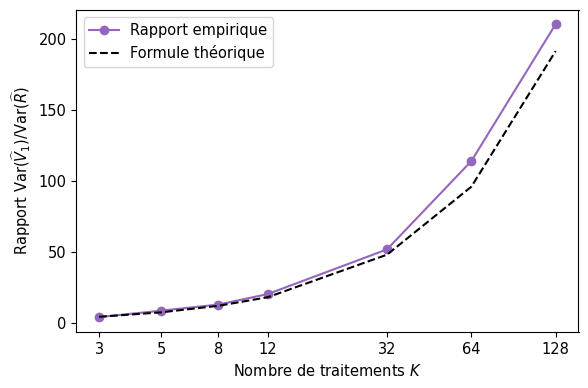

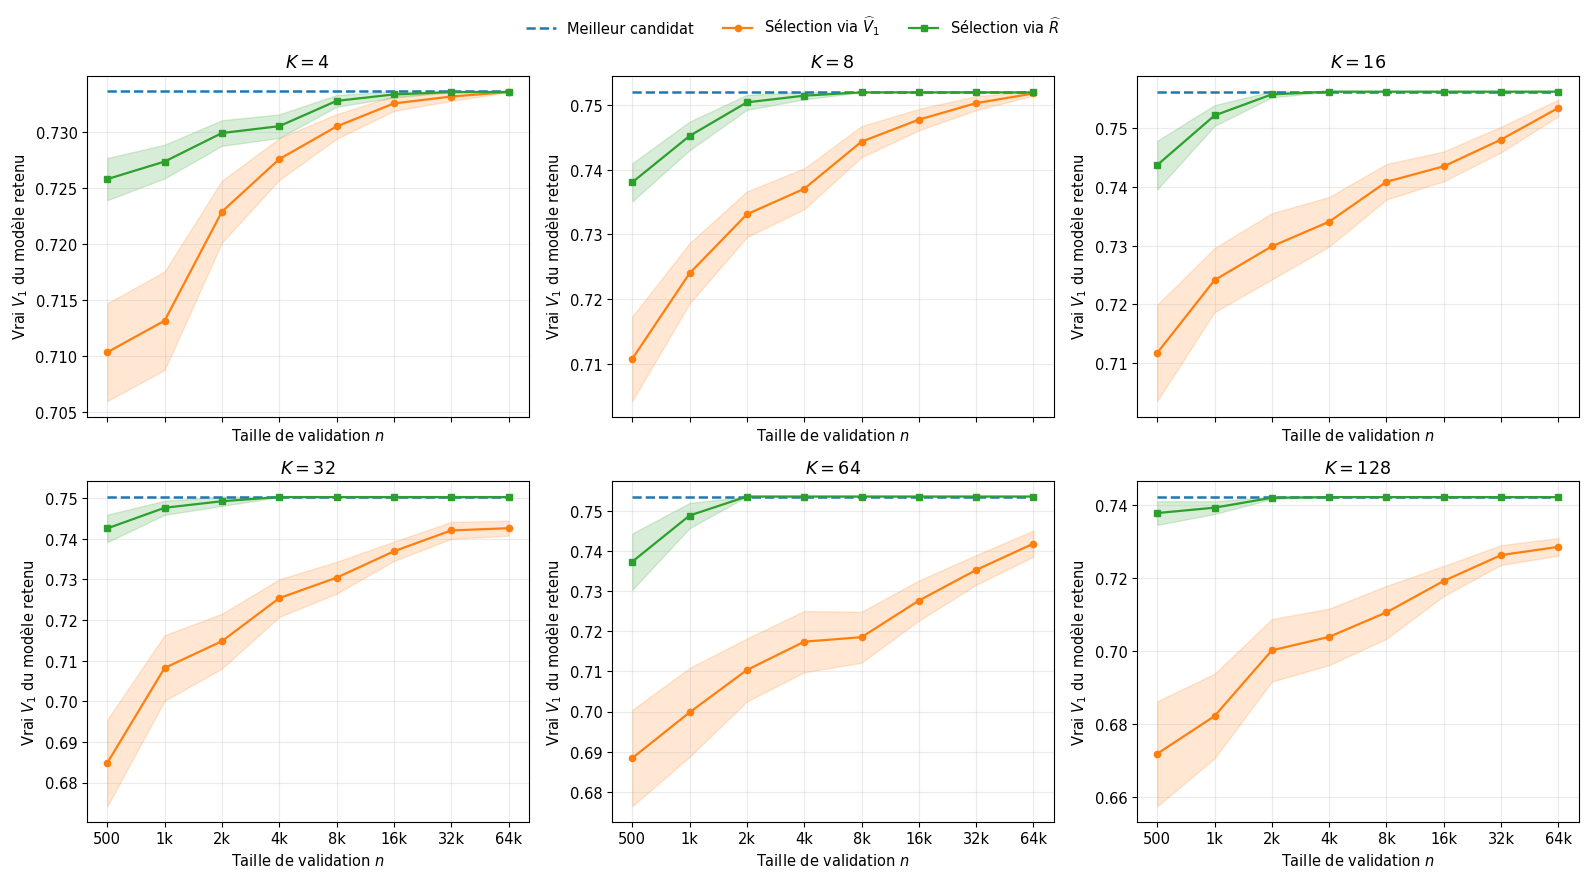

In [4]:
def fit_linear_tlearner(X, T, Y, K, features=(0, 1)):
    D = np.column_stack([np.ones(len(X)), X[:, list(features)]])
    coef = []
    for t in range(K):
        m = (T == t)
        A = D[m]
        y = Y[m]
        reg = np.eye(D.shape[1]) * 1e-4
        reg[0, 0] = 0
        coef.append(np.linalg.solve(A.T @ A + reg, A.T @ y))
    return np.asarray(coef), tuple(features)


def predict_linear(models, X):
    coefs, features = models
    D = np.column_stack([np.ones(len(X)), X[:, list(features)]])
    return np.clip(D @ coefs.T, 0.01, 0.99)


def experience_4_variance_et_grille_n():
    rng = np.random.default_rng(SEED + 5)

    rows_var = []
    for K in K_VARIANCE:
        n = 1000
        v1_list, r_list, pop_list = [], [], []
        for _ in range(REPS):
            X, mu = dgp_zones_competitives(n, K, rng)
            order = rank_from_scores(mu)
            T, Y = rand_trial(mu, rng)
            vh = ipw_values(order, T, Y, K)
            v1_list.append(vh[0])
            r_list.append(vh @ weights(K))
            pop_list.append(oracle_values(order, mu))

        V = np.mean(pop_list, axis=0)
        w = weights(K)
        R_val = V @ w
        tv1 = (K * V[0] - V[0] ** 2) / n
        tR = (K * np.dot(w * w, V) - R_val ** 2) / n

        rows_var.append({
            "K": K,
            "ratio_emp": np.var(v1_list, ddof=1) / np.var(r_list, ddof=1),
            "ratio_theorie": tv1 / tR
        })

    df_var = pd.DataFrame(rows_var)
    save_table(df_var, "exp4_ratio_variance")

    plt.figure(figsize=(6, 4))
    plt.plot(df_var.K, df_var.ratio_emp, "o-", color="tab:purple", label="Rapport empirique")
    plt.plot(df_var.K, df_var.ratio_theorie, "k--", label="Formule théorique")
    plt.xscale("log", base=2)
    plt.xticks(K_VARIANCE, K_VARIANCE)
    plt.xlabel("Nombre de traitements $K$")
    plt.ylabel(r"Rapport $\mathrm{Var}(\widehat{V}_1) / \mathrm{Var}(\widehat{R})$")
    plt.legend()
    savefig("ratio_variance_K")

    candidate_specs = [
        ("Linéaire (X1, X2)", lambda X, T, Y, K: fit_linear_tlearner(X, T, Y, K, (0, 1)), predict_linear),
        ("Linéaire (X1 seul)", lambda X, T, Y, K: fit_linear_tlearner(X, T, Y, K, (0,)), predict_linear),
        ("Linéaire (X2 seul)", lambda X, T, Y, K: fit_linear_tlearner(X, T, Y, K, (1,)), predict_linear),
        ("Arbre prof=2", lambda X, T, Y, K: TLearner(DecisionTreeRegressor(max_depth=2, random_state=SEED)).fit(X, T, Y, K), lambda m, X: m.predict(X)),
        ("Arbre prof=4", lambda X, T, Y, K: TLearner(DecisionTreeRegressor(max_depth=4, random_state=SEED)).fit(X, T, Y, K), lambda m, X: m.predict(X)),
        ("Arbre prof=8", lambda X, T, Y, K: TLearner(DecisionTreeRegressor(max_depth=8, random_state=SEED)).fit(X, T, Y, K), lambda m, X: m.predict(X)),
        ("k-NN k=3", lambda X, T, Y, K: TLearner(KNeighborsRegressor(n_neighbors=3)).fit(X, T, Y, K), lambda m, X: m.predict(X)),
        ("k-NN k=15", lambda X, T, Y, K: TLearner(KNeighborsRegressor(n_neighbors=15)).fit(X, T, Y, K), lambda m, X: m.predict(X)),
        ("Forêt 15 arbres", lambda X, T, Y, K: TLearner(RandomForestRegressor(n_estimators=15, max_depth=3, random_state=SEED)).fit(X, T, Y, K), lambda m, X: m.predict(X)),
        ("Lasso α=0.05", lambda X, T, Y, K: TLearner(Lasso(alpha=0.05)).fit(X, T, Y, K), lambda m, X: m.predict(X)),
    ]

    K_grid_paradox = [4, 8, 16, 32, 64, 128]
    paradox_records = []
    sel_ab_records = []
    sel_detailed_records = []

    REPS_PARADOX = max(REPS, 120)

    for K in K_grid_paradox:
        ntrain = max(5000, 120 * K)
        Xtr, mutr = dgp_zones_competitives(ntrain, K, rng)
        Ttr, Ytr = rand_trial(mutr, rng)
        Xtest, mutest = dgp_zones_competitives(12000, K, rng)

        fitted_models = []
        true_v1s = []

        for name, fit_fn, pred_fn in candidate_specs:
            mod = fit_fn(Xtr, Ttr, Ytr, K)
            scores_te = pred_fn(mod, Xtest)
            order_te = rank_from_scores(scores_te)
            true_v1s.append(oracle_values(order_te, mutest)[0])
            fitted_models.append((mod, pred_fn))

        true_v1s = np.array(true_v1s)
        best_oracle_v1 = true_v1s.max()

        X_v_pool, mu_v_pool = dgp_zones_competitives(max(N_GRID), K, rng)
        orders_pool = [rank_from_scores(pred_fn(mod, X_v_pool)) for mod, pred_fn in fitted_models]

        for n_val in N_GRID:
            v1_chosen_by_v1 = []
            v1_chosen_by_r = []
            wins_ab_v1 = 0
            wins_ab_r = 0
            wins_correct_v1 = 0
            wins_correct_r = 0

            for _ in range(REPS_PARADOX):
                idx = rng.integers(0, len(X_v_pool), size=n_val)
                mu_sub = mu_v_pool[idx]
                Tv, Yv = rand_trial(mu_sub, rng)

                est_v1 = []
                est_r = []

                for m_idx in range(len(fitted_models)):
                    ov = orders_pool[m_idx][idx]
                    vh = ipw_values(ov, Tv, Yv, K)
                    est_v1.append(vh[0])
                    est_r.append(vh @ weights(K))

                if est_v1[0] > est_v1[1]:
                    wins_ab_v1 += 1
                if est_r[0] > est_r[1]:
                    wins_ab_r += 1

                chosen_v1 = int(np.argmax(est_v1))
                chosen_r = int(np.argmax(est_r))
                best_idx = int(np.argmax(true_v1s))
                wins_correct_v1 += int(chosen_v1 == best_idx)
                wins_correct_r += int(chosen_r == best_idx)
                v1_chosen_by_v1.append(true_v1s[chosen_v1])
                v1_chosen_by_r.append(true_v1s[chosen_r])

            taux_v1_val = 100 * wins_ab_v1 / REPS_PARADOX
            taux_r_val = 100 * wins_ab_r / REPS_PARADOX

            sel_ab_records.append({
                "K": K,
                "n": n_val,
                "Taux_candidat_0_prefere_au_1_V1_pct": taux_v1_val,
                "Taux_candidat_0_prefere_au_1_R_pct": taux_r_val
            })

            sel_detailed_records.append({
                "K": K,
                "n": n_val,
                "Taux_Selection_Correcte_V1_pct": 100 * wins_correct_v1 / REPS_PARADOX,
                "Taux_Selection_Correcte_R_pct": 100 * wins_correct_r / REPS_PARADOX
            })

            paradox_records.append({
                "K": K,
                "n": n_val,
                "V1_optimal": best_oracle_v1,
                "V1_sel_V1_mean": np.mean(v1_chosen_by_v1),
                "V1_sel_V1_std": 1.96 * np.std(v1_chosen_by_v1, ddof=1) / np.sqrt(REPS_PARADOX),
                "V1_sel_R_mean": np.mean(v1_chosen_by_r),
                "V1_sel_R_std": 1.96 * np.std(v1_chosen_by_r, ddof=1) / np.sqrt(REPS_PARADOX)
            })

    df_sel = pd.DataFrame(sel_ab_records)
    df_paradox = pd.DataFrame(paradox_records)
    df_detailed = pd.DataFrame(sel_detailed_records)

    save_table(df_sel, "exp4_taux_selection_grille_n")
    save_table(df_paradox, "exp4_paradoxe_grille_n")
    save_table(df_detailed, "exp4_taux_selection_detaille_par_K_et_n")

    fig, axs = plt.subplots(2, 3, figsize=(16, 9), sharex=True)
    axs = axs.ravel()

    xlabels = ["500", "1k", "2k", "4k", "8k", "16k", "32k", "64k"]

    for ax, k_val in zip(axs, K_grid_paradox):
        sub = df_paradox[df_paradox.K == k_val].sort_values("n")

        ax.plot(
            sub.n,
            sub.V1_optimal,
            "--",
            color="tab:blue",
            linewidth=1.8,
            label="Meilleur candidat"
        )

        ax.plot(
            sub.n,
            sub.V1_sel_V1_mean,
            "o-",
            color="tab:orange",
            linewidth=1.6,
            markersize=4.5,
            label=r"Sélection via $\widehat{V}_1$"
        )
        ax.fill_between(
            sub.n,
            sub.V1_sel_V1_mean - sub.V1_sel_V1_std,
            sub.V1_sel_V1_mean + sub.V1_sel_V1_std,
            color="tab:orange",
            alpha=0.18
        )

        ax.plot(
            sub.n,
            sub.V1_sel_R_mean,
            "s-",
            color="tab:green",
            linewidth=1.6,
            markersize=4.5,
            label=r"Sélection via $\widehat{R}$"
        )
        ax.fill_between(
            sub.n,
            sub.V1_sel_R_mean - sub.V1_sel_R_std,
            sub.V1_sel_R_mean + sub.V1_sel_R_std,
            color="tab:green",
            alpha=0.18
        )

        ax.set_xscale("log", base=2)
        ax.set_xticks(N_GRID)
        ax.set_xticklabels(xlabels)
        ax.set_title(rf"$K = {k_val}$")
        ax.set_xlabel("Taille de validation $n$")
        ax.set_ylabel(r"Vrai $V_1$ du modèle retenu")
        ax.grid(True, alpha=0.25)

    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.98))

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig(OUT / "paradoxe_croisement_selon_n_2x3.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

    return df_var, df_sel, df_paradox, df_detailed


df_var, df_sel, df_paradox, df_detailed = experience_4_variance_et_grille_n()